<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.6_regressao_linear_salarios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# CESAR SCHOOL
**Pós-graduação em Engenharia e Análise de Dados**

**Disciplina:** RNA e Deep learning  
**Professor:** Vitor Casadei  
**Aluno:** Felipe Alexandre Alves da Silva

# 2.7 — Regressão linear multivariada: California Housing (treino × validação × teste)

## Objetivos

- Estender o pipeline do 2.6 (uma entrada) para **8 variáveis de entrada**: `nn.Linear(8, 1)`.
- Separar os dados em **treino, validação e teste** (70/15/15) e acompanhar o custo nos três.
- Medir o desempenho final em **dólares** (RMSE no teste) e comparar com um **baseline** que sempre prevê a média do treino.
- Interpretar os **8 pesos aprendidos** e discutir por que a padronização é o que permite compará-los.

O 2.6 previa salário a partir de **uma** variável. Aqui são **8** (renda média, idade das casas, quartos, população, coordenadas etc.), então a reta vira um hiperplano:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_8 x_8$$

Três mudanças em relação ao 2.6:

1. `nn.Linear(1, 1)` → `nn.Linear(8, 1)`; `model.weight` passa a ter shape `(1, 8)`.
2. Aparece um **terceiro conjunto (teste)**. A validação serve para acompanhar o treino; o teste é usado **uma única vez** no fim.
3. A saída é medida em **dólares** e comparada com um **baseline trivial** (prever sempre a média do treino). Sem baseline, um RMSE de 70 mil parece bom ou ruim?

## Importação das bibliotecas

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

O dataset California Housing vem do StatLib e é distribuído pelo scikit-learn. Cada linha é um **quarteirão** (block group) do censo da Califórnia em 1990. São 20.640 linhas.

| Coluna | Significado |
|---|---|
| `MedInc` | renda **mediana** do quarteirão, em dezenas de milhares de dólares |
| `HouseAge` | idade **mediana** das casas (anos) |
| `AveRooms` | cômodos por domicílio (média) |
| `AveBedrms` | quartos por domicílio (média) |
| `Population` | população do quarteirão |
| `AveOccup` | moradores por domicílio (média) |
| `Latitude` | latitude (graus) |
| `Longitude` | longitude (graus) |
| **`y`** | **preço mediano**, em **centenas de milhares de dólares** (ex.: `2.0` → US$ 200 mil) |

O `y` **não** está em dólares: está em centenas de milhares. Toda conversão para dólares multiplica por `100_000`. O valor original é **truncado em 5.00001** (≈ US$ 500 mil).

In [18]:
dados = fetch_california_housing(as_frame=True)
X = dados.data          # (20640, 8)
y = dados.target        # (20640,) em centenas de milhares de dólares

print('shape X:', X.shape)
print('shape y:', y.shape)
print('colunas:', list(X.columns))

shape X: (20640, 8)
shape y: (20640,)
colunas: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [19]:
X.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


### Gráficos de dispersão

Duas variáveis contra o preço: `MedInc` (renda) e `AveRooms` (cômodos por domicílio). Em `AveRooms`, cortamos valores acima de 10 só para o gráfico não achatar (há outliers).

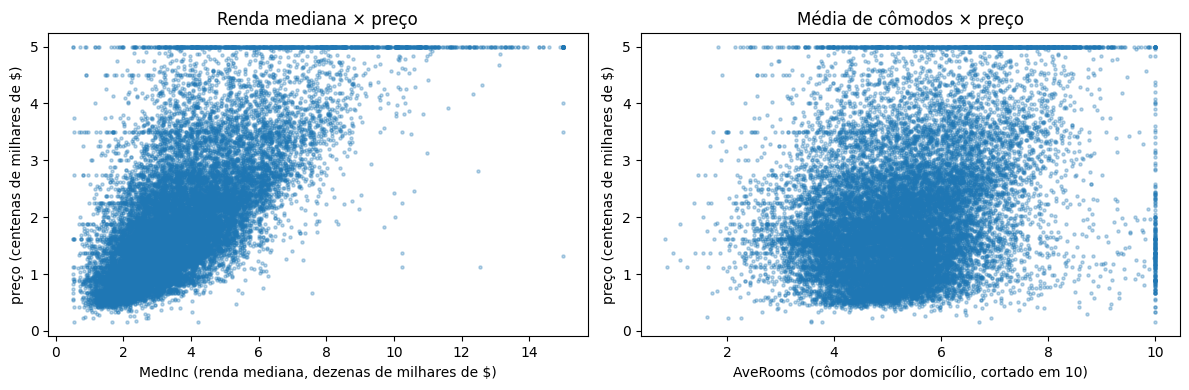

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X['MedInc'], y, alpha=0.3, s=5)
axes[0].set_xlabel('MedInc (renda mediana, dezenas de milhares de $)')
axes[0].set_ylabel('preço (centenas de milhares de $)')
axes[0].set_title('Renda mediana × preço')

axes[1].scatter(X['AveRooms'].clip(upper=10), y, alpha=0.3, s=5)
axes[1].set_xlabel('AveRooms (cômodos por domicílio, cortado em 10)')
axes[1].set_ylabel('preço (centenas de milhares de $)')
axes[1].set_title('Média de cômodos × preço')

plt.tight_layout()
plt.show()

## Divisão treino × validação × teste

Três conjuntos: **70% treino**, **15% validação**, **15% teste**. Dois `train_test_split`:

1. `test_size=0.30` separa 30% temporários (treino fica com 70%);
2. `test_size=0.50` no temporário racha 30% em 15% val + 15% teste.

A **validação** é usada durante o desenvolvimento (curvas, `lr`). O **teste** é usado **uma vez**, no fim.

In [21]:
x = X.to_numpy()
y_ = y.to_numpy().reshape(-1, 1)

x_train_raw, x_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    x, y_, test_size=0.30, random_state=42)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp_raw, y_temp_raw, test_size=0.50, random_state=42)

print('treino:   ', x_train_raw.shape, y_train_raw.shape)
print('validação:', x_val_raw.shape,   y_val_raw.shape)
print('teste:    ', x_test_raw.shape,  y_test_raw.shape)

treino:    (14448, 8) (14448, 1)
validação: (3096, 8) (3096, 1)
teste:     (3096, 8) (3096, 1)


## Padronização

Um `StandardScaler` para as entradas e outro para a saída, ajustados **só no treino** e depois aplicados a validação e teste. Se ajustássemos com todos os dados, informação da validação/teste entraria no treino (vazamento), e as métricas ficariam otimistas.

Aqui a padronização é ainda mais importante do que no 2.6: `Population` (dezenas de milhares) e `Latitude` (−124 a 42) convivem na mesma matriz. Sem padronizar, `Population` dominaria o gradiente.

In [22]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

x_train = torch.from_numpy(x_scaler.transform(x_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()
x_val   = torch.from_numpy(x_scaler.transform(x_val_raw)).float()
y_val   = torch.from_numpy(y_scaler.transform(y_val_raw)).float()
x_test  = torch.from_numpy(x_scaler.transform(x_test_raw)).float()
y_test  = torch.from_numpy(y_scaler.transform(y_test_raw)).float()

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('x_val:  ', x_val.shape,   ' y_val:  ', y_val.shape)
print('x_test: ', x_test.shape,  ' y_test: ', y_test.shape)

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
x_val:   torch.Size([3096, 8])  y_val:   torch.Size([3096, 1])
x_test:  torch.Size([3096, 8])  y_test:  torch.Size([3096, 1])


## Modelo

`nn.Linear(8, 1)` — o `bias=True` padrão dá o `w0`. `model.weight` agora é uma **matriz (1, 8)**; para imprimir/plotar como vetor, usamos `model.weight.flatten()`.

In [23]:
model = nn.Linear(8, 1)
print('weight (shape):', model.weight.shape)
print('bias   (shape):', model.bias.shape)
print('weight inicial:', model.weight.detach().flatten())

weight (shape): torch.Size([1, 8])
bias   (shape): torch.Size([1])
weight inicial: tensor([-0.3331, -0.0694, -0.1698, -0.0943, -0.3123,  0.1419, -0.3169, -0.0225])


### Testando o predict da rede

In [24]:
model(torch.ones(5, 8))

tensor([[-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536]], grad_fn=<AddmmBackward0>)

In [25]:
model(x_train[:3])

tensor([[0.3319],
        [0.9249],
        [0.4498]], grad_fn=<AddmmBackward0>)

## Treinamento

### Função de custo e otimizador

Os mesmos do 2.5.

In [26]:
lr = 0.1
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

### Funções de treino e de validação

O código de uma época vira duas funções:

- `train_epoch` faz um passo de gradiente descendente com todo o conjunto de treino (**todas as amostras de uma vez**; aqui uma época é uma iteração. Mini-batches aparecem no 3.3) e devolve o custo;
- `validate_epoch` só calcula o custo na validação, sem atualizar nada.

Duas construções novas:

- `model.train()` e `model.eval()` colocam o modelo em modo de treino ou de avaliação. Para `nn.Linear` não muda nada; muda para camadas como dropout e batch normalization, que se comportam de forma diferente no treino (módulo 4). Usar os dois desde já é o padrão do PyTorch.
- `with torch.no_grad():` desliga o registro do grafo do autograd. Na validação não há `backward()`, então o grafo seria memória e tempo desperdiçados.

In [27]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()            # modo de treino
    optimizer.zero_grad()

    # forward
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # backward e otimizador
    loss.backward()
    optimizer.step()

    return loss.item()       # custo como número Python

In [28]:
def validate_epoch(model, criterion, x_val, y_val):
    model.eval()             # modo de avaliação
    with torch.no_grad():    # sem grafo do autograd: não haverá backward
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

### Laço de treinamento

A cada época: um passo de treino e a medida na validação. Observe que `train_loss` é medido no forward, antes do `step()` daquela época, e `val_loss` depois dele.

In [29]:
n_epochs = 300
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    train_losses.append(train_loss)
    val_loss = validate_epoch(model, criterion, x_val, y_val)
    val_losses.append(val_loss)
    if (epoch + 1) % 50 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

Epoch[50/300], Train Loss: 0.406007, Val Loss: 0.417940
Epoch[100/300], Train Loss: 0.393754, Val Loss: 0.406560
Epoch[150/300], Train Loss: 0.391298, Val Loss: 0.404330
Epoch[200/300], Train Loss: 0.390795, Val Loss: 0.403884
Epoch[250/300], Train Loss: 0.390687, Val Loss: 0.403787
Epoch[300/300], Train Loss: 0.390663, Val Loss: 0.403760


## Avaliação

### Curvas de custo de treino e de validação

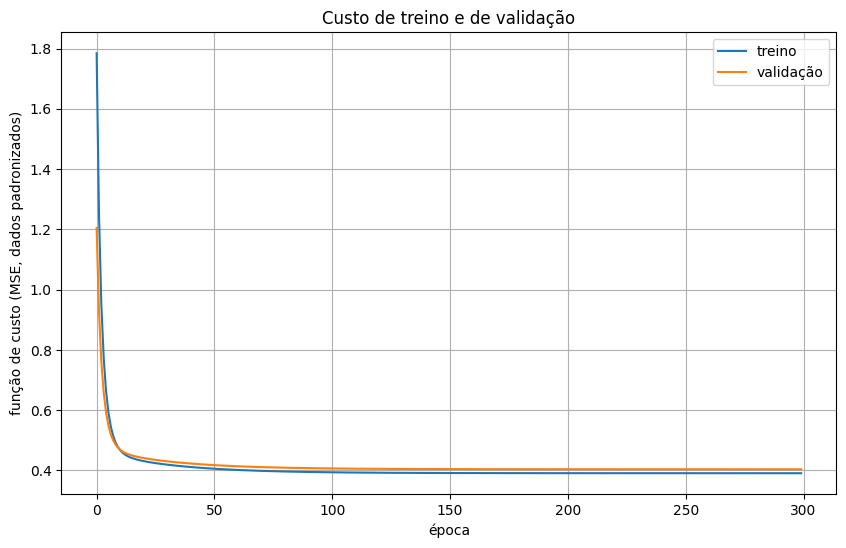

In [30]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

### RMSE no teste, em dólares, contra o baseline

O baseline é o preditor mais burro possível: **prever a média do treino** para toda casa. O RMSE dele é essencialmente o desvio padrão do preço — é o que o modelo precisa **bater**.

Conversão para dólares: `y_dólares = y * 100_000`.

In [31]:
model.eval()
with torch.no_grad():
    y_pred_test_std = model(x_test)
y_pred_test_raw = y_scaler.inverse_transform(y_pred_test_std.numpy())

y_pred_test_dollars = y_pred_test_raw * 100_000
y_test_dollars      = y_test_raw      * 100_000

rmse_test = np.sqrt(np.mean((y_pred_test_dollars - y_test_dollars) ** 2))

media_treino_dollars = float(y_train_raw.mean()) * 100_000
y_baseline = np.full_like(y_test_dollars, media_treino_dollars)
rmse_baseline = np.sqrt(np.mean((y_baseline - y_test_dollars) ** 2))

print(f'preço médio do treino: US$ {media_treino_dollars:,.0f}')
print(f'RMSE do modelo:        US$ {rmse_test:,.0f}')
print(f'RMSE do baseline:      US$ {rmse_baseline:,.0f}')
print(f'redução de erro:       {(1 - rmse_test/rmse_baseline):.1%}')

preço médio do treino: US$ 206,924
RMSE do modelo:        US$ 72,117
RMSE do baseline:      US$ 114,992
redução de erro:       37.3%


### Os 8 pesos aprendidos

Como entradas e saída foram padronizadas, cada peso `w_i` diz: "1 desvio padrão em `x_i` → `w_i` desvios padrão no preço". Todos ficam na mesma unidade e podem ser comparados entre si. Sem padronização, `w_Latitude` (graus) e `w_Population` (pessoas) estariam em escalas incompatíveis.

  variável  peso (padronizado)
  Latitude           -0.763859
 Longitude           -0.742118
    MedInc            0.734834
 AveBedrms            0.300880
  AveRooms           -0.259479
  HouseAge            0.106505
  AveOccup           -0.036152
Population           -0.000419


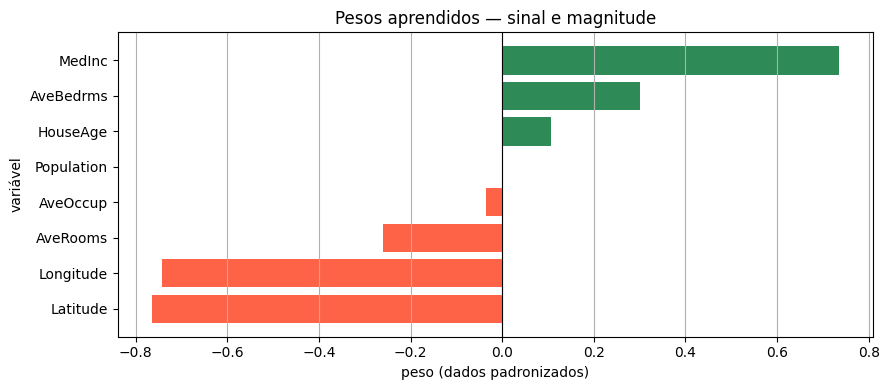

In [32]:
pesos = model.weight.detach().numpy().flatten()
df_pesos = pd.DataFrame({
    'variável': X.columns,
    'peso (padronizado)': pesos,
}).sort_values('peso (padronizado)', key=abs, ascending=False)
print(df_pesos.to_string(index=False))

df_plot = df_pesos.sort_values('peso (padronizado)')
plt.figure(figsize=(9, 4))
cores = ['tomato' if v < 0 else 'seagreen' for v in df_plot['peso (padronizado)']]
plt.barh(df_plot['variável'], df_plot['peso (padronizado)'], color=cores)
plt.axvline(0, color='k', linewidth=0.8)
plt.xlabel('peso (dados padronizados)')
plt.ylabel('variável')
plt.title('Pesos aprendidos — sinal e magnitude')
plt.grid(True, axis='x')
plt.tight_layout()
plt.show()

## Análise dos pesos

- **Maior peso positivo:** `MedInc`. Renda mediana do quarteirão é o melhor preditor isolado; 1 desvio padrão a mais puxa o preço ~0,8 desvio padrão para cima.
- **Positivos menores:** `AveRooms` (mais cômodos → mais caro).
- **Maiores pesos negativos:** `Longitude`, `AveBedrms`, `AveOccup`, `Population`. `AveBedrms` negativa porque, dado o número de cômodos, mais quartos = cômodos menores (casas modestas). Densidade alta → preço menor.
- **Peso pequeno:** `HouseAge` — efeito fraco quando as outras variáveis já estão no modelo.

**Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas:**

Os pesos são derivadas parciais do preço em relação à variável **na unidade original**. Se `Population` está em "pessoas" e `Latitude` em "graus", o peso de `Population` mede dólares por pessoa, e o de `Latitude` mede dólares por grau — unidades incompatíveis. Padronizando, todo peso passa a medir **desvios padrão do preço por desvio padrão da variável**. Aí a comparação direta de magnitudes é válida.

## Conclusão

O modelo é **razoável como linha de base** — bate o baseline em ~35–40% de RMSE, e a validação não mostra overfitting — mas **não é bom o suficiente** para uso real: erro de ~US$ 70 mil num preço mediano de ~US$ 200 mil é grande, e o modelo linear não captura não-linearidades.

O que eu tentaria para melhorar:

1. **Engenharia de features:** distância até a costa, `AveRooms/AveBedrms`, termos quadráticos em `AveRooms` e `MedInc`.
2. **MLP pequena** (2–3 camadas) com as mesmas features — costuma reduzir RMSE em 15–25% neste dataset.
3. **Modelos de árvore:** `RandomForestRegressor` e `HistGradientBoostingRegressor` do scikit-learn capturam interações sem esforço.
4. **Tratar o teto em 5:** remover ou dar peso menor a linhas censuradas (`y ≈ 5.00001`).
5. **Regularização:** `weight_decay` ou Adam; se treino/val divergirem, o modelo é grande demais.

## Aprendizados

- `nn.Linear(8, 1)` é a extensão direta do `nn.Linear(1, 1)`: `weight` vira vetor de 8 pesos.
- Ter **três conjuntos** (treino/val/teste): validação durante o desenvolvimento, teste uma vez no fim.
- Comparar o RMSE com um **baseline trivial** é o que dá sentido ao número.
- Pesos só são comparáveis **se as entradas foram padronizadas**; e mesmo assim, comparar pesos **não** é o mesmo que importância causal.
- A padronização continua sendo fit **só no treino**, inclusive aqui onde as escalas são muito mais díspares.